# 从 ¹³C NMR 解析结构

根据 NMR 峰表和分子式生成候选结构。

NMRTransformer 的谱编码器将峰表转为表征，分子解码器通过 beam search 生成 SMILES。每个候选附有分子式一致性和解码分数。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.generation.c')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.generation.c
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `h_nmr / c_nmr` | C 谱记录：位移（ppm）及原记录中的多重性、积分、J 值；按模态掩码选择输入。 |
| `formula` | 此 checkpoint 必须显式提供已知分子式。 |
| `beam_size` | 解码候选数；本页实验使用 5。 |

| Field | Meaning |
| --- | --- |
| `candidates` | 生成 SMILES、规范结构、有效性、分子式一致性及模型分数。 |
| `exact_match` | 与参考分子规范结构的一致性。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "formula": "C22H28",
    "h_nmr": [],
    "c_nmr": [
      {
        "type": "13C NMR",
        "chemical_shift": "150.22, 148.03, 142.68, 138.28, 128.36, 128.22, 125.68, 125.58, 125.12, 111.51, 35.72, 35.03, 34.46, 31.32, 31.11, 27.93"
      }
    ],
    "modality_mask": [
      0,
      1
    ]
  },
  "reference_smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
  "candidates": [
    {
      "smiles": "C=C(CCc1ccc(C(C)(C)C)cc1)CCc1ccccc1",
      "canonical_smiles": "C=C(CCc1ccccc1)CCc1ccc(C(C)(C)C)cc1",
      "score": -2.8281531435108036,
      "valid": true,
      "formula_match": true
    },
    {
      "smiles": "C=C(c1ccc(C(C)(C)C)cc1)c1ccc(C(C)(C)C)cc1",
      "canonical_smiles": "C=C(c1ccc(C(C)(C)C)cc1)c1ccc(C(C)(C)C)cc1",
      "score": -3.3919860787640914,
      "valid": true,
      "formula_match": true
    },
    {
      "smiles": "C=C(CCc1ccccc1)c1ccc(C(C)(C)C)cc1CC",
      "canonical_smiles": "C=C(CCc1ccccc1)c1ccc(C(C)(C)C)cc1CC",
      "score": -3.7319607

## 评估预测

用规范化结构的 top-k 准确率与有效 SMILES 比例汇总生成结果。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| nmrspec_test | recorded model | modality | available |
| nmrspec_test | recorded model | examples | 32 |
| nmrspec_test | recorded model | skipped_missing_modality | 0 |
| nmrspec_test | recorded model | valid | 31 |
| nmrspec_test | recorded model | formula_match | 23 |
| nmrspec_test | recorded model | exact | 3 |
| nmrspec_test | recorded model | valid_rate | 0.96875 |
| nmrspec_test | recorded model | formula_match_rate | 0.71875 |
| nmrspec_test | recorded model | exact_rate | 0.09375 |
| patent_test_10k | recorded model | modality | available |
| patent_test_10k | recorded model | examples | 32 |
| patent_test_10k | recorded model | skipped_missing_modality | 0 |
| patent_test_10k | recorded model | valid | 28 |
| patent_test_10k | recorded model | formula_match | 3 |
| patent_test_10k | recorded model | exact | 0 |
| patent_test_10k | recorded model | valid_rate | 0.875 |
| patent_test_10k | recorded model | formula_match_rate | 0.09375 |
| patent_test_10k | recorded model | exact_rate | 0 |
| nmrexp_exp_10k | recorded model | modality | available |
| nmrexp_exp_10k | recorded model | examples | 32 |
| nmrexp_exp_10k | recorded model | skipped_missing_modality | 0 |
| nmrexp_exp_10k | recorded model | valid | 32 |
| nmrexp_exp_10k | recorded model | formula_match | 30 |
| nmrexp_exp_10k | recorded model | exact | 19 |
| nmrexp_exp_10k | recorded model | valid_rate | 1 |
| nmrexp_exp_10k | recorded model | formula_match_rate | 0.9375 |
| nmrexp_exp_10k | recorded model | exact_rate | 0.59375 |
| nmrgym_test | recorded model | modality | available |
| nmrgym_test | recorded model | examples | 32 |
| nmrgym_test | recorded model | skipped_missing_modality | 0 |
| nmrgym_test | recorded model | valid | 30 |
| nmrgym_test | recorded model | formula_match | 16 |
| nmrgym_test | recorded model | exact | 0 |
| nmrgym_test | recorded model | valid_rate | 0.9375 |
| nmrgym_test | recorded model | formula_match_rate | 0.5 |
| nmrgym_test | recorded model | exact_rate | 0 |


{
  "top1_matches_reference_this_example": false
}


## 查看结果图

参考结构与生成候选。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

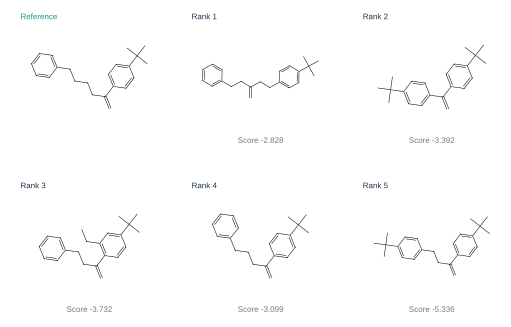

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.generation.c', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.generation.c --limit 8 --output results/nmr-generation-c.json
```

[Task](../tasks/nmr-generation-c.md) · [Quick start](../quickstart.md)



## 参考文献

- Yang, L., Yang, Z., Xie, J., Wang, Y., Gao, B., Fu, T., Wei, X., Sun, J., Wu, J., He, C., Li, Y. & Gu, Q. NMRTrans: Structure Elucidation from Experimental NMR Spectra via Set Transformers. arXiv:2602.10158 (2026). [Source](https://arxiv.org/abs/2602.10158)
- Fang, Z., Yang, C., Yu, H., Luo, H., He, H., Xie, J., Yang, Z. & Xia, J. NMRGym: A Comprehensive Benchmark for Nuclear Magnetic Resonance Based Molecular Structure Elucidation. arXiv:2601.15763 (2026). [Source](https://arxiv.org/abs/2601.15763)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
